
# Data Processing – INX Future Inc. Employee Performance Analysis

## 1. Project Overview

This project analyzes employee performance at INX Future Inc. The objective is to understand employee-related factors associated with performance ratings and prepare the dataset for exploratory data analysis and machine learning.

## 2. Objectives

- Load the employee performance dataset.
- Understand the dataset structure.
- Check for missing values and duplicate records.
- Verify data types and data quality.
- Prepare the dataset for further analysis and model building.

## 3. Tools and Libraries

- Python
- Pandas
- NumPy
- Jupyter Notebook


In [1]:

import pandas as pd
from pathlib import Path

DATA_PATH = Path("../../data/raw")

# Excel file ka path automatically find karo
files = list(DATA_PATH.glob("*.xls"))

print("Excel files found:", files)


Excel files found: [WindowsPath('../../data/raw/INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls')]


In [2]:

import pandas as pd
from pathlib import Path

# Dataset path
DATA_PATH = Path("../../data/raw/INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls")

# Load dataset
df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first 5 rows
df.head()


Dataset loaded successfully!
Dataset shape: (1200, 28)


,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


In [3]:

# Display column names
print("Column Names:")
print(df.columns.tolist())

# Check dataset structure and data types
print("\nDataset Information:")
df.info()


Column Names:
['EmpNumber', 'Age', 'Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked', 'OverTime', 'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear', 'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany', 'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'Attrition', 'PerformanceRating']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                    

In [4]:

# Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("\nTotal duplicate rows:", df.duplicated().sum())

# Check duplicate employee IDs
print("\nDuplicate employee IDs:", df["EmpNumber"].duplicated().sum())


Missing values per column:
EmpNumber                       0
Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

Total m

## 4. Data Quality Check

The dataset contains 1,200 records and 28 columns. No missing values were found in any column. There are no duplicate rows or duplicate employee IDs. Therefore, missing-value treatment and duplicate removal are not required at this stage.

In [5]:
# Identify categorical and numerical columns

categorical_cols = df.select_dtypes(include="object").columns.tolist()
numerical_cols = df.select_dtypes(include="number").columns.tolist()

print("Categorical columns:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical columns:", len(numerical_cols))
print(numerical_cols)

Categorical columns: 9
['EmpNumber', 'Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'OverTime', 'Attrition']

Numerical columns: 19
['Age', 'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked', 'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear', 'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany', 'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'PerformanceRating']


In [6]:
# Check unique values in categorical columns

for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values")
    print(df[col].unique())
    print("-" * 50)

EmpNumber: 1200 unique values
['E1001000' 'E1001006' 'E1001007' ... 'E100994' 'E100995' 'E100998']
--------------------------------------------------
Gender: 2 unique values
['Male' 'Female']
--------------------------------------------------
EducationBackground: 6 unique values
['Marketing' 'Life Sciences' 'Human Resources' 'Medical' 'Other'
 'Technical Degree']
--------------------------------------------------
MaritalStatus: 3 unique values
['Single' 'Married' 'Divorced']
--------------------------------------------------
EmpDepartment: 6 unique values
['Sales' 'Human Resources' 'Development' 'Data Science'
 'Research & Development' 'Finance']
--------------------------------------------------
EmpJobRole: 19 unique values
['Sales Executive' 'Manager' 'Developer' 'Sales Representative'
 'Human Resources' 'Senior Developer' 'Data Scientist'
 'Senior Manager R&D' 'Laboratory Technician' 'Manufacturing Director'
 'Research Scientist' 'Healthcare Representative' 'Research Director'
 'Man

In [7]:
# Check target variable distribution

print("Performance Rating Counts:")
print(df["PerformanceRating"].value_counts().sort_index())

print("\nPerformance Rating Percentage:")
print(
    (df["PerformanceRating"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Performance Rating Counts:
PerformanceRating
2    194
3    874
4    132
Name: count, dtype: int64

Performance Rating Percentage:
PerformanceRating
2    16.17
3    72.83
4    11.00
Name: proportion, dtype: float64


## 5. Target Variable Analysis

The target variable is `PerformanceRating`, with three classes: 2, 3, and 4.

- Rating 2: 194 employees (16.17%)
- Rating 3: 874 employees (72.83%)
- Rating 4: 132 employees (11.00%)

Rating 3 represents 72.83% of the dataset, indicating class imbalance. During model evaluation, accuracy will be considered along with precision, recall, and F1-score.

In [8]:
# Statistical summary of numerical columns

df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1200.0,36.918333,9.087289,18.0,30.0,36.0,43.0,60.0
DistanceFromHome,1200.0,9.165833,8.176636,1.0,2.0,7.0,14.0,29.0
EmpEducationLevel,1200.0,2.892500,1.044120,1.0,2.0,3.0,4.0,5.0
EmpEnvironmentSatisfaction,1200.0,2.715833,1.090599,1.0,2.0,3.0,4.0,4.0
EmpHourlyRate,1200.0,65.981667,20.211302,30.0,48.0,66.0,83.0,100.0
EmpJobInvolvement,1200.0,2.731667,0.707164,1.0,2.0,3.0,3.0,4.0
EmpJobLevel,1200.0,2.067500,1.107836,1.0,1.0,2.0,3.0,5.0
EmpJobSatisfaction,1200.0,2.732500,1.100888,1.0,2.0,3.0,4.0,4.0
NumCompaniesWorked,1200.0,2.665000,2.469384,0.0,1.0,2.0,4.0,9.0
EmpLastSalaryHikePercent,1200.0,15.222500,3.625918,11.0,12.0,14.0,18.0,25.0


In [9]:
# Check logical consistency of experience columns

print(
    "Company experience greater than total experience:",
    (df["ExperienceYearsAtThisCompany"] >
     df["TotalWorkExperienceInYears"]).sum()
)

print(
    "Current role experience greater than company experience:",
    (df["ExperienceYearsInCurrentRole"] >
     df["ExperienceYearsAtThisCompany"]).sum()
)

print(
    "Manager experience greater than company experience:",
    (df["YearsWithCurrManager"] >
     df["ExperienceYearsAtThisCompany"]).sum()
)

Company experience greater than total experience: 0
Current role experience greater than company experience: 0
Manager experience greater than company experience: 0


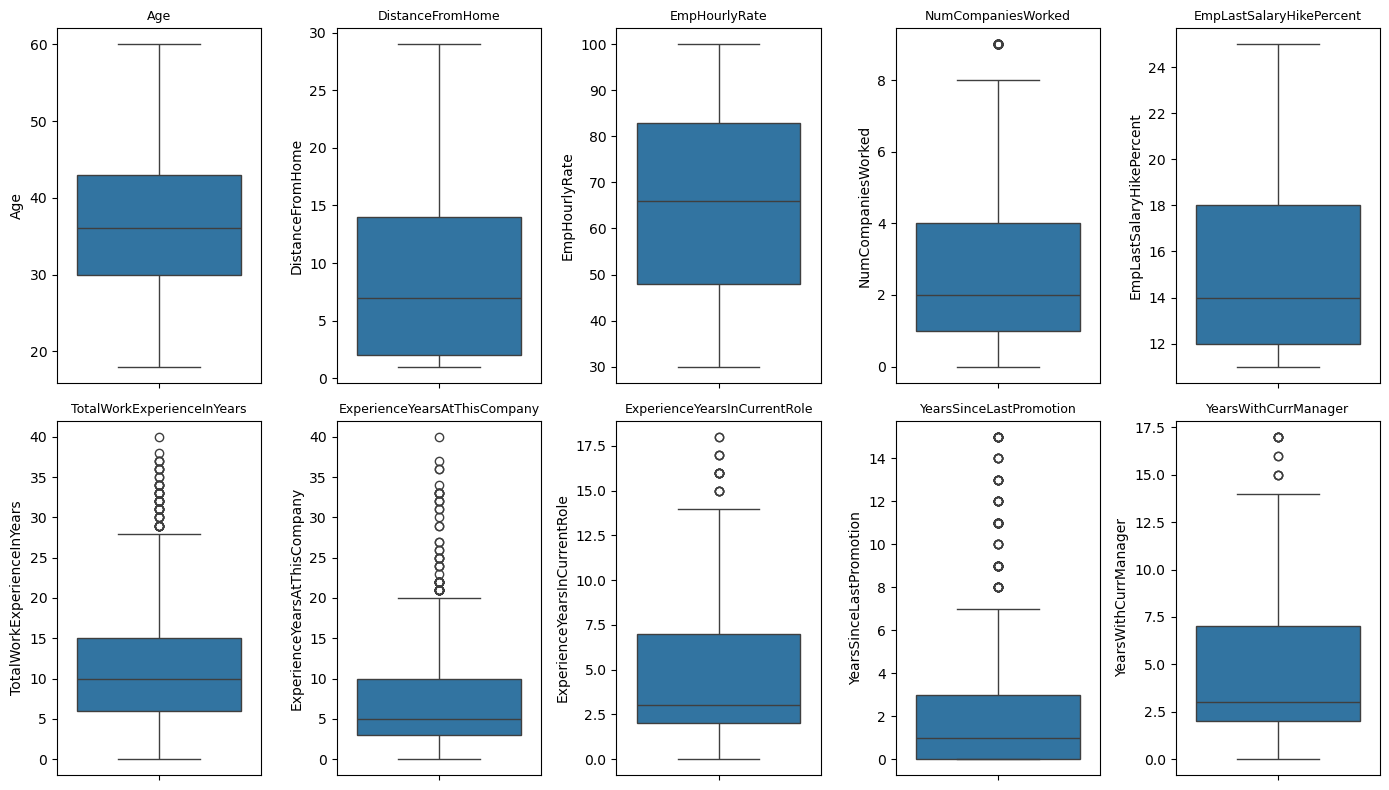

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select continuous numerical columns for outlier visualization
continuous_cols = [
    "Age",
    "DistanceFromHome",
    "EmpHourlyRate",
    "NumCompaniesWorked",
    "EmpLastSalaryHikePercent",
    "TotalWorkExperienceInYears",
    "ExperienceYearsAtThisCompany",
    "ExperienceYearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
]

plt.figure(figsize=(14, 8))

for i, col in enumerate(continuous_cols, 1):
    plt.subplot(2, 5, i)
    sns.boxplot(y=df[col])
    plt.title(col, fontsize=9)

plt.tight_layout()
plt.show()

In [11]:
from pathlib import Path

# Create processed folder if it does not exist
processed_dir = Path("../../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save processed dataset
output_path = processed_dir / "INX_employee_performance_processed.csv"
df.to_csv(output_path, index=False)

print("Processed dataset saved successfully!")
print("File path:", output_path.resolve())
print("Dataset shape:", df.shape)

Processed dataset saved successfully!
File path: C:\Users\HP\Desktop\Employee_Performance_Analysis1\data\processed\INX_employee_performance_processed.csv
Dataset shape: (1200, 28)
